# Exploratory data analysis

Goals:
- understand each variable: type, domain, distribution, missing values
- feed the fundamental analysis in `00_framing` (What, Who, When, Where, How, Why, red flags);
- study the target and its relationships with the features.

## Methods

- **Categorical variable vs churn:** churn rate per category, χ² test of independence (H0: no link, α = 5%, at least 5 expected counts per cell), and **Cramér's V** for the strength of the link (2-column tables: 0.1 weak, 0.3 moderate, 0.5 strong).
- **Continuous variable vs churn:** distributions by class, t-test (Welch unless stated), and the **gap between the means in standard deviations** for the strength.
- **With 114,863 customers in the train set, almost every test is significant (p < 0.001): the strength of the link is what matters.**
- **Leakage check:** a category covering many customers with a churn rate close to 0% or 100% would signal leakage. Measurement dates are unknown (see `00_framing`).
- **Limitation:** hypotheses were tested on the same data that suggested them (confirmation bias).

## 1. Setup

In [290]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind

In [291]:
data = pd.read_csv("../data/train_data.csv")        # labelled file (143,579 rows)
kaggle_test = pd.read_csv("../data/test_data.csv")  # ML-PRO test set, no target: never analysed

**Train / test split before any analysis.** The ML-PRO test set has no target, so an internal test set is needed for the final evaluation. It is set aside now (20%, purely random split with a fixed `random_state`, not stratified so that the target is not used at all) and **never used in this EDA**. Churn rate: 21.2% in train, 21.4% in test. The same split is recreated in `02_modeling`.

The whole EDA uses `train` only. Exception: section 4 (data origin) checks where the whole file comes from, without studying the target.

In [292]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.2, random_state=42)
print("labelled file:", data.shape, "| train:", train.shape, "| internal test (set aside):", test.shape)
print(f"churn rate: train {train['Exited'].mean():.1%} | test {test['Exited'].mean():.1%}")

labelled file: (143579, 14) | train: (114863, 14) | internal test (set aside): (28716, 14)
churn rate: train 21.2% | test 21.4%


In [293]:
def churn_by_category(df, col, target="Exited"):
    """Distribution of a categorical variable, churn rate per category,
    chi-square test of independence and Cramér's V."""
    print("Distribution:")
    print(df[col].value_counts(normalize=True).sort_index().round(3))

    rate = pd.crosstab(df[col], df[target], normalize="index")[1]
    print("\nChurn rate:")
    print(rate.round(3))

    counts = pd.crosstab(df[col], df[target])
    result = chi2_contingency(counts)
    n = counts.values.sum()
    k = min(counts.shape)
    cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
    print(f"\nchi2 p-value: {result.pvalue:.3g} | min expected count: {result.expected_freq.min():.0f} | Cramér's V: {cramers_v:.3f}")

    overall = df[target].mean()
    rate.plot(kind="bar")
    plt.axhline(overall, color="red", linestyle="--", label=f"overall churn rate ({overall:.0%})")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.legend()
    plt.show()

In [294]:
def churn_by_continuous(df, col, target="Exited", equal_var=False):
    """Distribution of a continuous variable by class, boxplot, histograms
    and t-test comparing churners and non-churners
    (Welch by default; Student if equal_var=True)."""
    print(df.groupby(target)[col].describe().round(2))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(data=df, x=target, y=col, ax=axes[0])
    axes[0].set_title(f"{col} by {target}")
    sns.histplot(data=df, x=col, hue=target, stat="density", common_norm=False, ax=axes[1])
    axes[1].set_title(f"Distribution of {col} by {target}")
    plt.show()

    stayed = df.loc[df[target] == 0, col]
    left = df.loc[df[target] == 1, col]
    result = ttest_ind(stayed, left, equal_var=equal_var)
    print(f"Mean difference (churners - non-churners): {left.mean() - stayed.mean():.2f}")
    test_name = "Student" if equal_var else "Welch"
    print(f"{test_name} t-test p-value: {result.pvalue:.3g}")

## 2. Overview

In [295]:
print(f"train shape: {train.shape}")

train shape: (114863, 14)


In [296]:
train.head()

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
91348,108635,15606267,Wilson,622,France,Female,35.0,7,98640.74,2,1.0,1.0,110457.99,1
2636,147941,15644891,Pirozzi,752,France,Female,32.0,2,0.00,1,1.0,0.0,159843.24,0
117007,88744,15702464,Watson,710,France,Male,31.0,4,0.00,3,0.0,0.0,160548.66,1
100279,125789,15701605,L?,704,Germany,Male,46.0,4,138912.17,1,0.0,1.0,141804.78,1
34835,135997,15757577,Hs?,675,Germany,Female,51.0,8,143390.51,1,1.0,0.0,168034.90,1


In [297]:
train.info()

<class 'pandas.DataFrame'>
Index: 114863 entries, 91348 to 121958
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   ID               114863 non-null  int64  
 1   CustomerId       114863 non-null  int64  
 2   Surname          114863 non-null  str    
 3   CreditScore      114863 non-null  int64  
 4   Geography        114863 non-null  str    
 5   Gender           114863 non-null  str    
 6   Age              114863 non-null  float64
 7   Tenure           114863 non-null  int64  
 8   Balance          114863 non-null  float64
 9   NumOfProducts    114863 non-null  int64  
 10  HasCrCard        114863 non-null  float64
 11  IsActiveMember   114863 non-null  float64
 12  EstimatedSalary  114863 non-null  float64
 13  Exited           114863 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 13.1 MB


In [298]:
summary = pd.DataFrame({
    "dtype": train.dtypes,
    "n_unique": train.nunique(),
    "min": train.min(numeric_only=True),
    "max": train.max(numeric_only=True),
})
summary

,dtype,n_unique,min,max
Age,float64,70,18.00,92.00
Balance,float64,23278,0.00,250898.09
CreditScore,int64,455,350.00,850.00
CustomerId,int64,20150,15565701.00,15815690.00
EstimatedSalary,float64,42763,11.58,199992.48
Exited,int64,2,0.00,1.00
Gender,str,2,NaN,NaN
Geography,str,3,NaN,NaN
HasCrCard,float64,2,0.00,1.00
ID,int64,114863,0.00,165033.00


**Variable types**
- Identifiers (not features): `ID`, `CustomerId`
- Categorical / discrete: `Surname`, `Geography`, `Gender`, `NumOfProducts`, `Tenure`, `HasCrCard`, `IsActiveMember`
- Continuous: `CreditScore`, `Age`, `Balance`, `EstimatedSalary`
- Target: `Exited` (binary)

In [299]:
train.isna().sum()

ID                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

No missing values in any column.

## 3. Target

In [300]:
train["Exited"].value_counts(normalize=True)

Exited
0    0.788452
1    0.211548
Name: proportion, dtype: float64

<Axes: xlabel='Exited'>

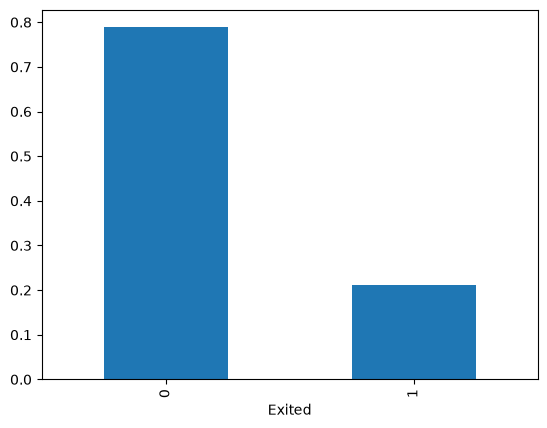

In [301]:
train["Exited"].value_counts(normalize=True).plot(kind="bar")

`Exited` is binary and imbalanced: about 21% churn (1) vs 79% stay (0).

## 4. Data origin

I compare our data with the Kaggle Playground competition [S4E1](https://www.kaggle.com/competitions/playground-series-s4e1/data), whose data is documented as *"generated from a deep learning model trained on the Bank Customer Churn Prediction dataset"*.

In [302]:
import kagglehub

path = kagglehub.competition_download("playground-series-s4e1")
s4e1 = pd.read_csv(path + "/train.csv")

summary_s4e1 = pd.DataFrame({
    "dtype": s4e1.dtypes,
    "n_unique": s4e1.nunique(),
    "min": s4e1.min(numeric_only=True),
    "max": s4e1.max(numeric_only=True),
})
summary_s4e1

,dtype,n_unique,min,max
Age,float64,71,18.00,92.00
Balance,float64,30075,0.00,250898.09
CreditScore,int64,457,350.00,850.00
CustomerId,int64,23221,15565701.00,15815690.00
EstimatedSalary,float64,55298,11.58,199992.48
Exited,int64,2,0.00,1.00
Gender,str,2,NaN,NaN
Geography,str,3,NaN,NaN
HasCrCard,float64,2,0.00,1.00
IsActiveMember,float64,2,0.00,1.00


In [303]:
# Our labelled file (all rows) vs the S4E1 train set
pd.DataFrame({
    "file n_unique": data.nunique(),
    "S4E1 n_unique": s4e1.rename(columns={"id": "ID"}).nunique(),
    "file min": data.min(numeric_only=True),
    "S4E1 min": s4e1.rename(columns={"id": "ID"}).min(numeric_only=True),
    "file max": data.max(numeric_only=True),
    "S4E1 max": s4e1.rename(columns={"id": "ID"}).max(numeric_only=True),
})

,file n_unique,S4E1 n_unique,file min,S4E1 min,file max,S4E1 max
Age,71,71,18.00,18.00,92.00,92.00
Balance,27258,30075,0.00,0.00,250898.09,250898.09
CreditScore,456,457,350.00,350.00,850.00,850.00
CustomerId,22017,23221,15565701.00,15565701.00,15815690.00,15815690.00
EstimatedSalary,50076,55298,11.58,11.58,199992.48,199992.48
Exited,2,2,0.00,0.00,1.00,1.00
Gender,2,2,NaN,NaN,NaN,NaN
Geography,3,3,NaN,NaN,NaN,NaN
HasCrCard,2,2,0.00,0.00,1.00,1.00
ID,143579,165034,0.00,0.00,165033.00,165033.00


**Comparison between our labelled file and the S4E1 train set:**
- **Row count**: S4E1 train has 165,034 rows (`id` from 0 to 165,033). Our labelled file + ML-PRO test = 143,579 + 21,455 = 165,034, and our `ID` also ranges from 0 to 165,033.
- **Unique values**: S4E1 always has slightly more unique values than our file (`CustomerId` 23,221 vs 22,017, `Surname` 2,797 vs 2,765, `Balance` 30,075 vs 27,258). This is consistent with our file being a subset of S4E1 (a subset cannot have more unique values), but it is not a proof.
- **Types**: same dtypes (e.g. `Age`, `HasCrCard`, `IsActiveMember` stored as float64 in both).
- **Ranges**: identical min and max for every numeric column, to the cent (e.g. `Balance` 0 to 250,898.09, `EstimatedSalary` 11.58 to 199,992.48, `Age` 18 to 92). A subset must stay within the ranges of the full set; here they are exactly the same.
- **Same artifacts**: `CustomerId` and `Surname` are not unique in S4E1 either.

These clues converge: our data is most likely a split of the S4E1 train set. **Next: verify it row by row** (merge on `ID` / `id`).

### Row-by-row check

For each row of our labelled file, find the S4E1 row with the same identifier (`ID` = `id`) and compare every column.

In [304]:
merged = data.merge(
    s4e1, left_on="ID", right_on="id", how="left",
    suffixes=("_ours", "_s4e1"), indicator=True,
)
print("rows in our file:", len(data))
print("rows found in S4E1:", (merged["_merge"] == "both").sum())

# For each column, count the rows where our value differs from the S4E1 value
cols = [c for c in data.columns if c != "ID"]
differences = pd.Series(
    {c: (merged[f"{c}_ours"] != merged[f"{c}_s4e1"]).sum() for c in cols},
    name="rows with a different value",
)
differences

rows in our file: 143579
rows found in S4E1: 143579


CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
Name: rows with a different value, dtype: int64

**Conclusion:** all 143,579 rows of our labelled file are found in the S4E1 train set, with **0 difference** in every column. Our labelled file is an exact subset of S4E1 (observed). The ML-PRO test set (21,455 rows) most likely contains the remaining S4E1 rows (same total, not checked row by row).

Consequence: our data is **synthetic**, generated by a deep learning model trained on the original churn dataset (S4E1 documentation). The generator details (model, how `CustomerId` and `Surname` were assigned) are not documented.

## 5. CustomerId

An identifier should be unique, but there are only 20,150 unique values for 114,863 rows (train).

In [305]:
train["CustomerId"].value_counts(sort=True)

CustomerId
15682355    87
15570194    75
15585835    67
15793331    67
15585067    65
            ..
15707837     1
15691389     1
15596808     1
15618782     1
15649859     1
Name: count, Length: 20150, dtype: int64

In [306]:
train[train["CustomerId"].isin([15682355, 15570194, 15585835])]

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
121600,65525,15585835,Hsueh,835,France,Male,42.0,7,0.00,2,1.0,0.0,147797.54,0
30686,111124,15570194,Chiang,659,France,Male,36.0,7,161802.16,1,0.0,1.0,176714.59,0
1787,30243,15682355,Frewin,694,France,Female,57.0,9,0.00,1,1.0,0.0,64869.76,1
95519,99274,15682355,Sabbatini,709,Germany,Male,39.0,3,75075.31,2,1.0,1.0,92888.52,0
121030,47787,15682355,Dilibe,708,France,Male,35.0,2,0.00,2,0.0,0.0,52693.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5695,24020,15682355,Lo,445,France,Male,37.0,6,112935.87,1,1.0,1.0,89017.38,0
30266,29673,15682355,Onyemauchechi,554,France,Male,55.0,5,0.00,1,1.0,0.0,156792.89,1
5698,92725,15585835,Toscani,637,France,Female,39.0,2,0.00,2,1.0,0.0,157959.37,0
70463,164134,15682355,Hsia,656,France,Male,47.0,5,0.00,2,1.0,0.0,170514.21,0


**`CustomerId` is not a real identifier.** Rows sharing an ID have nothing in common (surname, gender, country, age, tenure): the generator (section 4) produced IDs like any other column. Not used as a feature.

## 6. Surname

In [307]:
train["Surname"].value_counts(sort=True)

Surname
Hsia           1651
T'ien          1594
Hs?            1120
Kao            1104
Maclean        1099
               ... 
Ervin             1
Parkinson         1
Knupp             1
Kharitonova       1
Spinelli          1
Name: count, Length: 2707, dtype: int64

In [308]:
train[train["Surname"].isin(["Hsia", "T'ien", "Hs?"])]

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
34835,135997,15757577,Hs?,675,Germany,Female,51.0,8,143390.51,1,1.0,0.0,168034.90,1
90944,152826,15763414,T'ien,642,France,Female,42.0,9,0.00,1,1.0,1.0,162858.29,1
127693,91447,15582762,Hs?,740,France,Female,40.0,1,0.00,2,1.0,0.0,176780.39,0
20527,5744,15645896,T'ien,459,Spain,Female,27.0,5,70417.79,2,1.0,0.0,175843.68,0
65176,157964,15593764,Hsia,535,France,Male,35.0,4,0.00,2,1.0,1.0,115818.51,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91906,121971,15592751,Hs?,641,France,Male,24.0,4,0.00,2,0.0,1.0,177747.03,0
67172,43747,15811594,Hsia,611,France,Male,46.0,4,129718.57,1,1.0,1.0,141451.99,0
118451,87769,15686959,Hs?,705,Germany,Female,38.0,5,160599.70,2,1.0,0.0,132470.28,0
134633,76631,15766183,T'ien,666,Spain,Female,29.0,8,0.00,2,0.0,0.0,134936.84,0


**Encoding issue:** some surnames contain "?" (e.g. "Hs?"), non-ASCII characters were lost.

**Hypothesis:** if surnames were drawn at random **independently of the other columns**, each surname would follow the overall country split (57 / 22 / 21%).

In [309]:
train["Geography"].value_counts(normalize=True)

Geography
France     0.570192
Spain      0.220201
Germany    0.209606
Name: proportion, dtype: float64

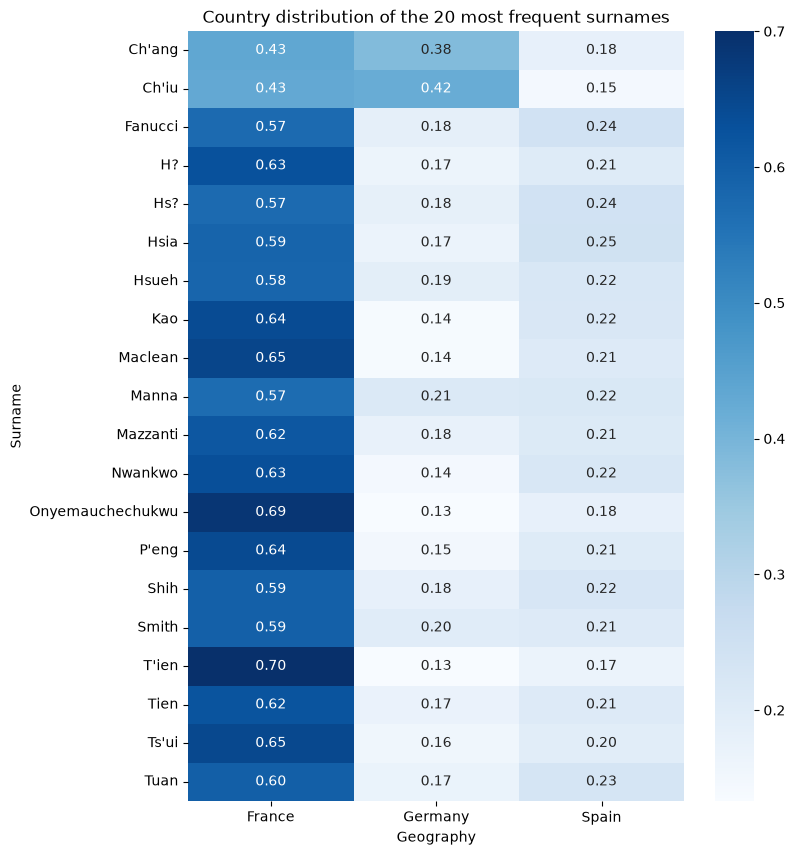

In [310]:
top_surnames = train["Surname"].value_counts().head(20).index
top = train[train["Surname"].isin(top_surnames)]
ct = pd.crosstab(top["Surname"], top["Geography"], normalize="index")

plt.figure(figsize=(8, 10))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues")
plt.title("Country distribution of the 20 most frequent surnames")
plt.show()

### χ² test: Surname × Geography

Surnames with fewer than 24 rows are excluded, so that every expected count is ≥ 5 (filter on the total per surname, not on the per-country counts, to avoid biasing the test).

In [311]:
cross_tab = pd.crosstab(train["Surname"], train["Geography"])
cross_tab_frequent = cross_tab[cross_tab.sum(axis=1) >= 24]

result = chi2_contingency(cross_tab_frequent)
print("surnames kept:", len(cross_tab_frequent))
print("customers covered:", cross_tab_frequent.values.sum())
print("p-value:", result.pvalue)
print("min expected count:", result.expected_freq.min())

# Strength of the link : Cramér's V, between 0 (no link) and 1 (perfect link)
n = cross_tab_frequent.values.sum()
k = min(cross_tab_frequent.shape)
cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
print("Cramér's V:", round(cramers_v, 3))

surnames kept: 680
customers covered: 100754
p-value: 0.0
min expected count: 5.057546102387994
Cramér's V: 0.189


**Weak-to-moderate link (V ≈ 0.19); independence rejected** (680 surnames, 100,754 customers; benchmarks for 3 columns: 0.07 / 0.21 / 0.35).
- Part of it is noise: V would already be about 0.08 under H0 with this many surnames. Most surnames follow the overall split, a few deviate.
- The generator partially preserved the surname–country links of the original data.

**Decision:** not used as a feature (no business meaning, possible proxy for ethnic origin, encoding issues), whatever the test result.

## 7. Geography

In [312]:
train["Geography"].value_counts(normalize=True)

Geography
France     0.570192
Spain      0.220201
Germany    0.209606
Name: proportion, dtype: float64

In [313]:
churn_by_country = pd.crosstab(train["Geography"], train["Exited"], normalize="index")[1]
churn_by_country

Geography
France     0.164565
Germany    0.380753
Spain      0.172142
Name: 1, dtype: float64

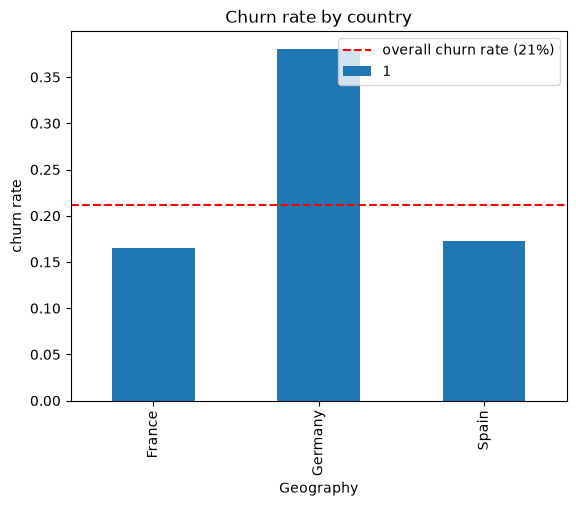

In [314]:
churn_by_country.plot(kind="bar")
plt.axhline(train["Exited"].mean(), color="red", linestyle="--", label="overall churn rate (21%)")
plt.ylabel("churn rate")
plt.title("Churn rate by country")
plt.legend()
plt.show()

**Germany churns about twice as much:** 38.1% vs 16.5% in France and 17.2% in Spain (overall 21%).

In [315]:
churn_by_country = pd.crosstab(train["Geography"], train["Exited"])
result = chi2_contingency(churn_by_country)

print("p-value:", result.pvalue)
print("min expected count:", result.expected_freq.min())

# Strength of the link : Cramér's V, between 0 (no link) and 1 (perfect link)
n = churn_by_country.values.sum()
k = min(churn_by_country.shape)
cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
print("Cramér's V:", round(cramers_v, 3))

p-value: 0.0
min expected count: 5093.221698893464
Cramér's V: 0.213


**Weak-to-moderate link (V = 0.21).** Why Germany? See section 18.1.

## 8. Gender

In [316]:
train["Gender"].value_counts(normalize=True)

Gender
Male      0.564716
Female    0.435284
Name: proportion, dtype: float64

<Axes: xlabel='Gender'>

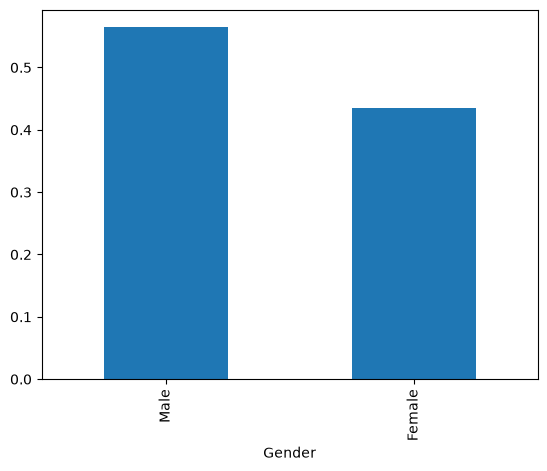

In [317]:
train["Gender"].value_counts(normalize=True).plot(kind="bar")

Gender
Female    0.279751
Male      0.158976
Name: 1, dtype: float64


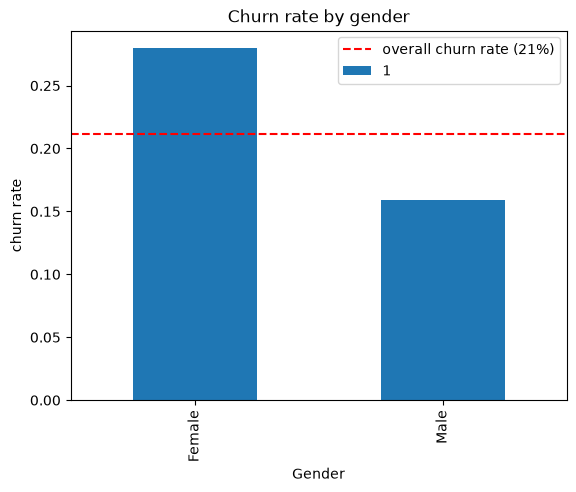

In [318]:
churn_by_gender_rate = pd.crosstab(train["Gender"], train["Exited"], normalize="index")[1]
print(churn_by_gender_rate)

churn_by_gender_rate.plot(kind="bar")
plt.axhline(train["Exited"].mean(), color="red", linestyle="--", label="overall churn rate (21%)")
plt.ylabel("churn rate")
plt.title("Churn rate by gender")
plt.legend()
plt.show()

**Women churn more:** 28.0% vs 15.9% for men (56% of customers are men).

In [319]:
churn_by_gender = pd.crosstab(train["Gender"], train["Exited"])
result = chi2_contingency(churn_by_gender)

print("p-value:", result.pvalue)
print("min expected count:", result.expected_freq.min())

# Strength of the link : Cramér's V, between 0 (no link) and 1 (perfect link)
n = churn_by_gender.values.sum()
k = min(churn_by_gender.shape)
cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
print("Cramér's V:", round(cramers_v, 3))

p-value: 0.0
min expected count: 10576.960396298198
Cramér's V: 0.147


**Weak link (V = 0.15).**

**Ethics:** this only describes the data. Using `Gender` as a feature is decided at feature selection (see `00_framing`).

## 9. NumOfProducts

Ordered (1 to 4 products).

Distribution:
NumOfProducts
1    0.469
2    0.510
3    0.018
4    0.003
Name: proportion, dtype: float64

Churn rate:
NumOfProducts
1    0.347
2    0.061
3    0.878
4    0.861
Name: 1, dtype: float64

chi2 p-value: 0 | min expected count: 68 | Cramér's V: 0.419


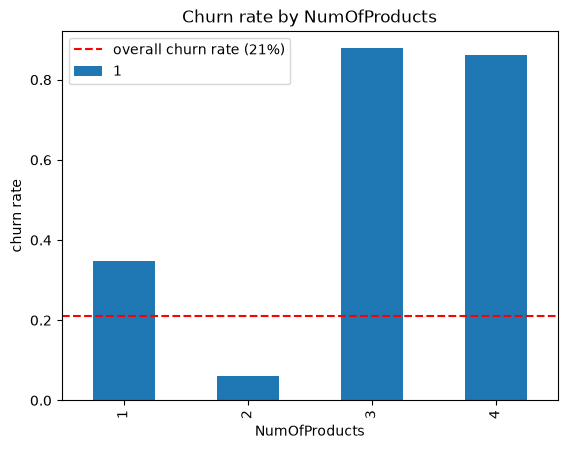

In [320]:
churn_by_category(train, "NumOfProducts")

**Moderate-to-strong link (V = 0.42), U-shaped: the strongest categorical variable.**

| Products | Share of customers | Churn rate |
|---|---|---|
| 1 | 46.9% | 34.7% |
| 2 | 51.0% | **6.1%** |
| 3 | 1.8% | **87.8%** |
| 4 | 0.3% | **86.1%** |

- Churn drops from 1 to 2 products, then jumps at 3–4: as a plain number (1, 2, 3, 4), a linear model would miss this shape.
- **Leakage:** no global leakage. At 3–4 products it is implausible (products are not opened when leaving). At 1 product (47% of customers) it is possible if products were closed one by one before leaving and measured late. Not verifiable.

## 10. HasCrCard

Binary (1 = has a credit card).

Distribution:
HasCrCard
0.0    0.245
1.0    0.755
Name: proportion, dtype: float64

Churn rate:
HasCrCard
0.0    0.228
1.0    0.206
Name: 1, dtype: float64

chi2 p-value: 6.44e-15 | min expected count: 5954 | Cramér's V: 0.023


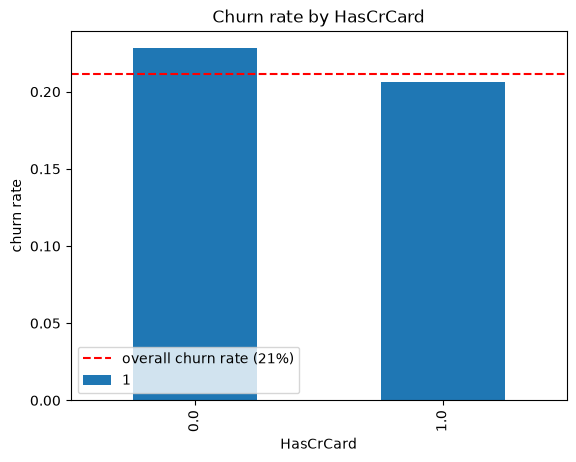

In [321]:
churn_by_category(train, "HasCrCard")

**Negligible link (V = 0.02).**
- Churn: 22.8% without a card vs 20.6% with a card (75% have one).
- Leakage risk negligible: closing the card before leaving would raise churn without a card, but the gap is only 2 points.

## 11. IsActiveMember

Binary (1 = active; "active" is not defined).

Distribution:
IsActiveMember
0.0    0.503
1.0    0.497
Name: proportion, dtype: float64

Churn rate:
IsActiveMember
0.0    0.297
1.0    0.125
Name: 1, dtype: float64

chi2 p-value: 0 | min expected count: 12078 | Cramér's V: 0.211


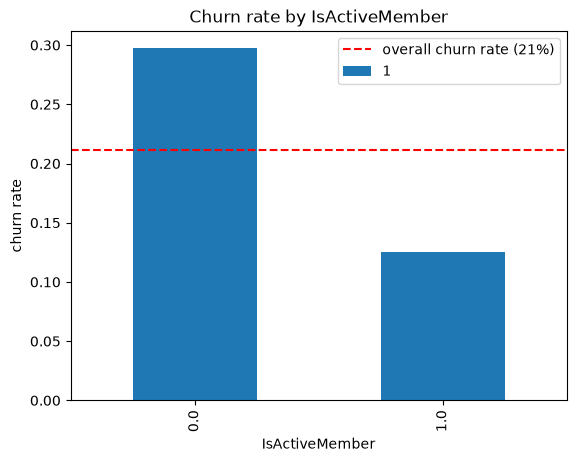

In [322]:
churn_by_category(train, "IsActiveMember")

**Weak-to-moderate link (V = 0.21); main leakage risk.**
- Churn: **29.7%** inactive vs **12.5%** active (50/50 split).
- No global leakage (70% of inactive members stay), but inactivity can be a *consequence* of leaving: if measured at or after the churn, part of the link is leakage. Not verifiable.

## 12. Tenure

Discrete (0 to 10 years), treated as categorical.

Distribution:
Tenure
0     0.031
1     0.102
2     0.109
3     0.101
4     0.106
5     0.105
6     0.095
7     0.108
8     0.107
9     0.102
10    0.036
Name: proportion, dtype: float64

Churn rate:
Tenure
0     0.260
1     0.228
2     0.195
3     0.230
4     0.227
5     0.218
6     0.196
7     0.187
8     0.199
9     0.212
10    0.213
Name: 1, dtype: float64



chi2 p-value: 5.07e-39 | min expected count: 747 | Cramér's V: 0.042


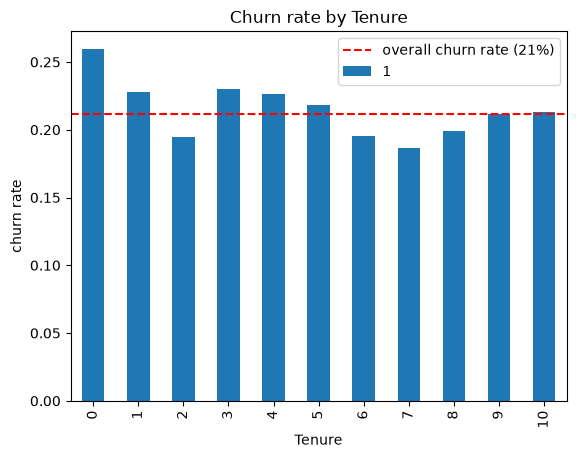

In [323]:
churn_by_category(train, "Tenure")

**Negligible link (V = 0.04).**
- Churn stays between 19% and 26% with no trend (new customers slightly higher: 26.0%); almost uniform distribution.
- Surprising for a real bank, where long-standing customers should leave less: the values look like random draws.

## Summary: categorical variables vs churn

| Variable | Churn rate per category | Cramér's V | Link | Leakage risk |
|---|---|---|---|---|
| `NumOfProducts` | 1: 34.7% · 2: 6.1% · 3: 87.8% · 4: 86.1% | 0.42 | moderate to strong, U-shaped | possible at 1 product (gradual closing) |
| `Geography` | France 16.5% · Spain 17.2% · Germany 38.1% | 0.21 | weak to moderate | low |
| `IsActiveMember` | inactive 29.7% · active 12.5% | 0.21 | weak to moderate | **most serious** (inactivity can follow churn) |
| `Gender` | female 28.0% · male 15.9% | 0.15 | weak | low (ethical question) |
| `Tenure` | between 18.7% and 26.0%, no trend | 0.04 | negligible | low |
| `HasCrCard` | without 22.8% · with 20.6% | 0.02 | negligible | negligible |

**Why do German customers churn more?** See section 18.1.

## 13. Balance

In [324]:
train["Balance"].describe()

count    114863.000000
mean      55624.554866
std       62825.062047
min           0.000000
25%           0.000000
50%           0.000000
75%      120037.960000
max      250898.090000
Name: Balance, dtype: float64

<Axes: ylabel='Frequency'>

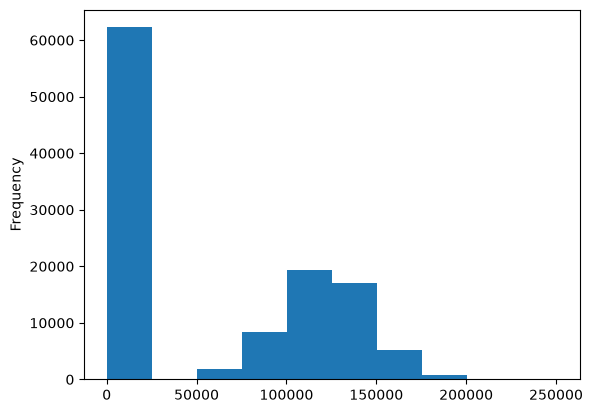

In [325]:
train["Balance"].plot(kind="hist")

**Two populations:** at least half of the customers have a zero balance; positive balances are bell-shaped around 120,000.
→ Binary variable `has_balance` (1 if `Balance` > 0), studied without modifying `train`.

Distribution:
has_balance
0    0.542
1    0.458
Name: proportion, dtype: float64

Churn rate:
has_balance
0    0.161
1    0.271
Name: 1, dtype: float64



chi2 p-value: 0 | min expected count: 11131 | Cramér's V: 0.134


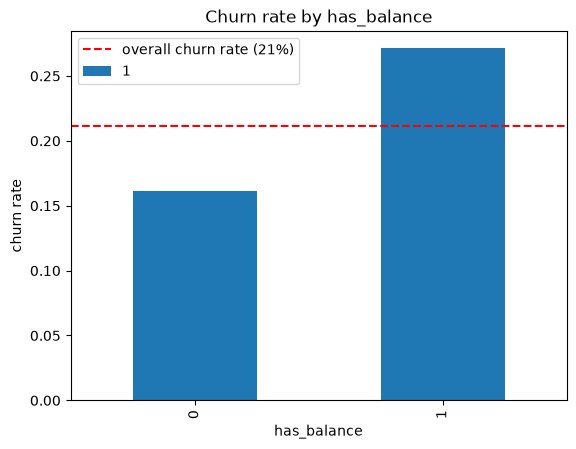

In [326]:
churn_by_category(
    train.assign(has_balance=(train["Balance"] > 0).astype(int)),
    "has_balance",
)

**Weak link (V = 0.13): a positive balance churns more** (27.1% vs 16.1%; 54% of balances are zero).
- Leakage risk low: emptying the account before leaving would give *more* churn for zero balances; the opposite is observed.
- Business hypothesis (not verifiable): customers with money have more to gain by switching banks.

### Positive balances vs churn

Does the **amount** matter, among customers with a positive balance?

In [327]:
train.query("`Balance` > 0").groupby("Exited")["Balance"].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,38346.0,121277.683809,25536.140837,3768.69,103913.6900,122328.095,137961.4525,250898.09
1,14272.0,121825.194940,23574.612647,9904.42,106964.6975,122021.920,136487.8600,238387.56


<Axes: xlabel='Exited', ylabel='Balance'>

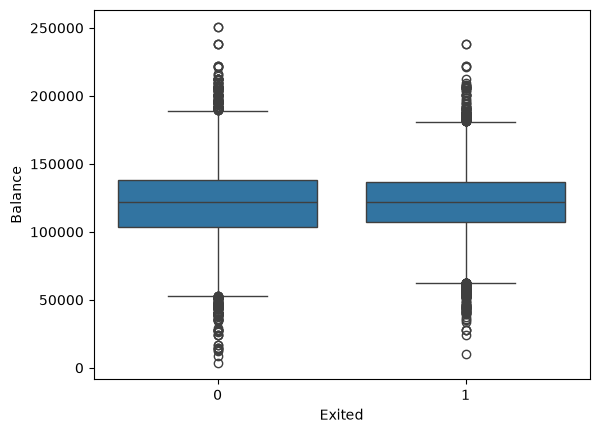

In [328]:
sns.boxplot(data=train.query("Balance > 0"), x="Exited", y="Balance")

<Axes: xlabel='Balance', ylabel='Density'>

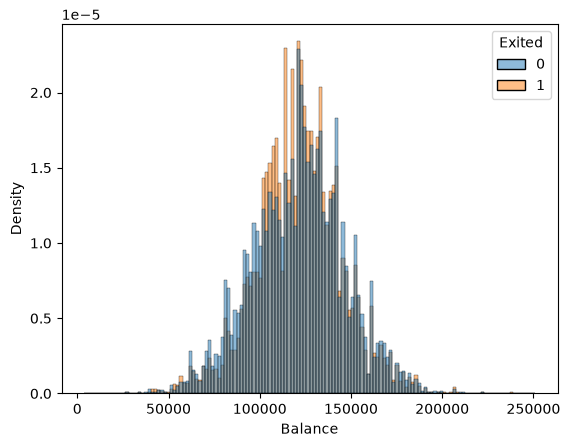

In [329]:
sns.histplot(
    data=train.query("Balance > 0"),
    x="Balance",
    hue="Exited",
    stat="density",
    common_norm=False,
)

**t-test:** H0 = same mean `Balance` for churners and non-churners (positive balances only). n > 30 per group and similar standard deviations (25,536 vs 23,575): Student t-test. i.i.d. not guaranteed (see `00_framing`).

In [330]:
ttest_ind(train.query("Balance > 0 & Exited == 0")["Balance"] , train.query("Balance > 0 & Exited == 1")["Balance"])

TtestResult(statistic=np.float64(-2.231786916667782), pvalue=np.float64(0.0256332432332913), df=np.float64(52616.0))

**Practically no difference in amount (p = 0.026, but a gap of only 547).**
- H0 is rejected at α = 5%, but the means are almost identical: 121,278 vs 121,825, a gap of about 0.02 standard deviation.
- The p-value is close to the threshold: a small change in the sample could push it above 0.05. Significance says nothing about practical importance.
- The information in `Balance` lies in zero vs positive, not in the amount → `has_balance`.

## 14. Age

Continuous (18 to 92).

          count   mean   std   min   25%   50%   75%   max
Exited                                                    
0       90564.0  36.59  8.17  18.0  31.0  36.0  40.0  92.0
1       24299.0  43.93  8.99  18.0  38.0  44.0  50.0  92.0


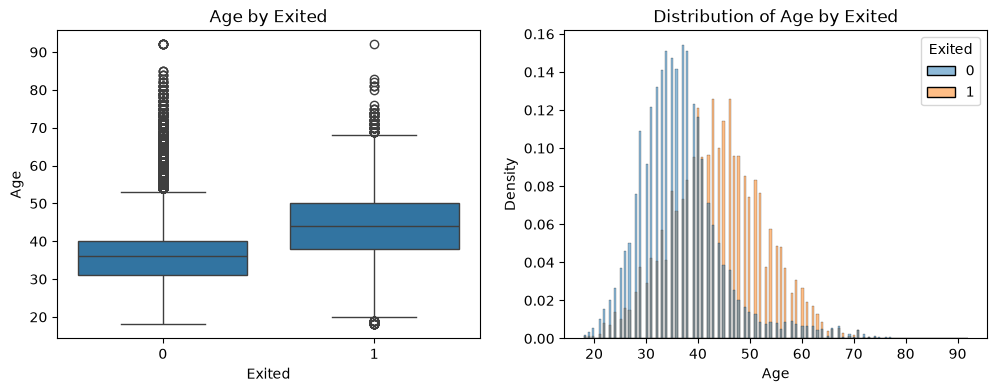

Mean difference (churners - non-churners): 7.34
Student t-test p-value: 0


In [331]:
churn_by_continuous(train, "Age", equal_var=True)

**Large gap: churners are 7.3 years older** (43.9 vs 36.6, about 0.83 standard deviation).
- Similar spreads (standard deviations 8.2 and 9.0), with a tail towards older ages. High ages are plausible outliers: kept for now (IQR at preprocessing).
- Not monotonic: churn peaks at 50–60 and drops after 60 (section 18.1 c).

## 15. CreditScore

Continuous (350 to 850); provider and calculation method not documented.

          count    mean    std    min    25%    50%    75%    max
Exited                                                           
0       90564.0  657.62  79.89  350.0  599.0  662.0  711.0  850.0
1       24299.0  652.33  81.15  350.0  593.0  652.0  708.0  850.0


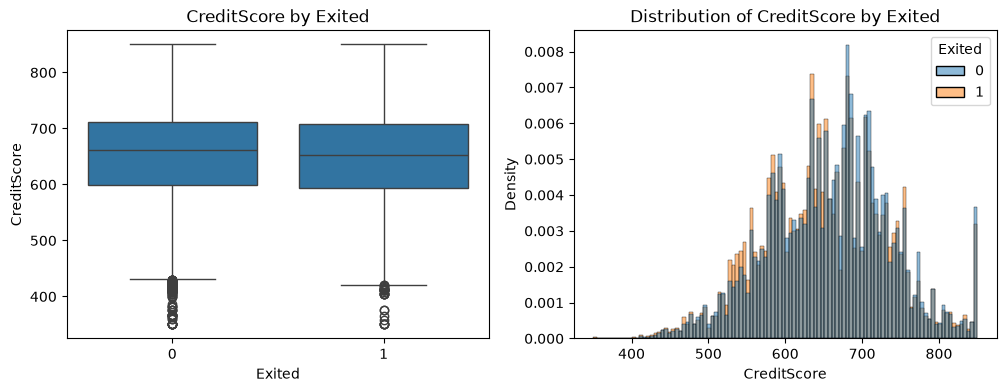

Mean difference (churners - non-churners): -5.30
Welch t-test p-value: 1.31e-19


In [332]:
churn_by_continuous(train, "CreditScore")

**Negligible gap (0.07 standard deviation):** 652.3 vs 657.6. Significant only because of the sample size; the distributions almost overlap.

## 16. EstimatedSalary

Continuous; an estimate, not a declared salary.

          count       mean       std    min       25%        50%        75%  \
Exited                                                                        
0       90564.0  112058.23  50193.35  11.58  74415.85  116970.50  153667.22   
1       24299.0  114087.18  50640.06  11.58  74849.82  120892.96  158427.80   

              max  
Exited             
0       199992.48  
1       199992.48  


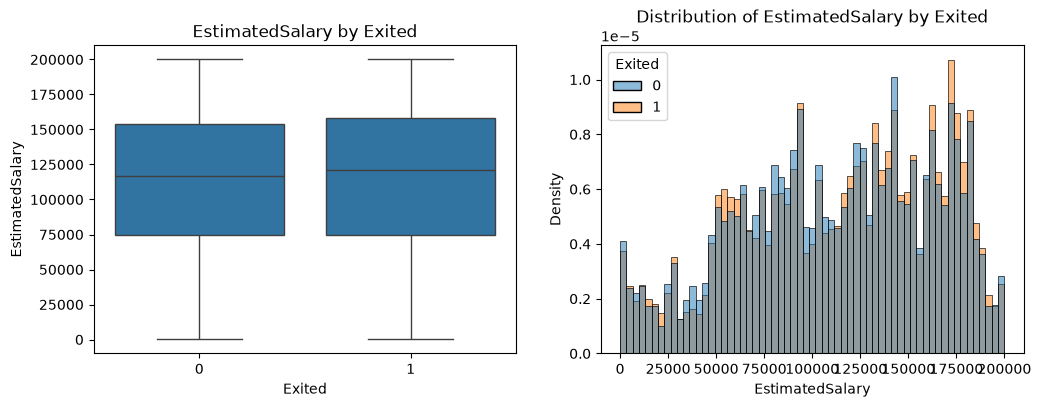

Mean difference (churners - non-churners): 2028.95
Welch t-test p-value: 2.78e-08


In [333]:
churn_by_continuous(train, "EstimatedSalary")

**Negligible gap (0.04 standard deviation):** 114,087 vs 112,058. Significant only because of the sample size.
- **Atypical distribution:** more high salaries than low ones, and 3% below 10,000 a year (minimum 11.58): probably not measured salaries.
- Not derived from `Balance` (correlation 0.008, section 17).

## 17. Correlations between continuous variables

Pearson correlation (linear links only); |r| > 0.8 would signal redundancy. `Tenure` is excluded: discrete, analysed as categorical (section 12).

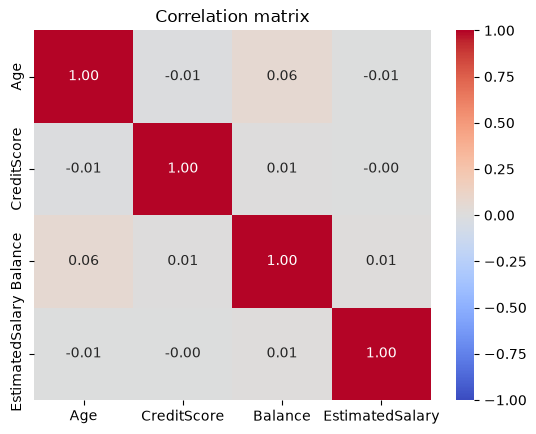

In [334]:
corr = train[["Age", "CreditScore", "Balance", "EstimatedSalary"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

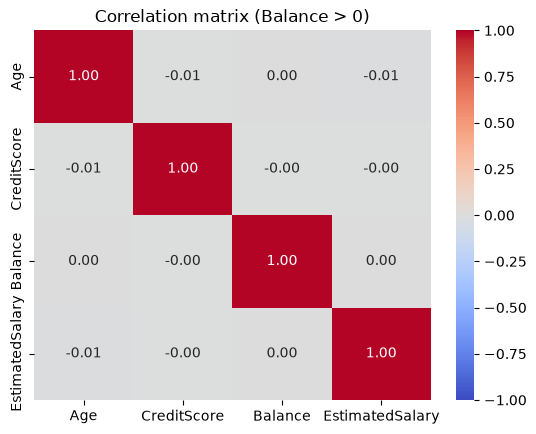

In [335]:
# Same matrix on positive balances only (removes the spike at 0)
corr_pos = train.query("Balance > 0")[["Age", "CreditScore", "Balance", "EstimatedSalary"]].corr()
sns.heatmap(corr_pos, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (Balance > 0)")
plt.show()

**No redundancy between continuous variables** (all |r| < 0.07).
- The highest, `Age` × `Balance` = 0.064, drops to 0.003 on positive balances: it came from the spike at 0.
- No multicollinearity issue for continuous variables; the redundancy is between categorical ones (section 18). Pearson only detects linear links.

## 18. Cross analyses

Each variable was first analysed alone (sections 7 to 17). This section crosses variables to answer two questions raised along the way.

**Method:** a variable can explain an effect only if (1) it differs across the groups compared (χ² test between features) and (2) once it is fixed, the effect disappears or shrinks (stratified analysis: compare churn rates within each stratum).

### 18.1 Why do German customers churn more?

Germany has a 38% churn rate vs about 17% in France and Spain (section 7). Three candidates, all linked to churn: `NumOfProducts` (section 9), `Balance` (section 13) and `Age` (section 14).

#### a. Number of products

In [336]:
pd.crosstab(train["Geography"], train["NumOfProducts"], normalize="index")

NumOfProducts,1,2,3,4
Geography,,,,
France,0.433108,0.551165,0.013726,0.002000
Germany,0.596320,0.368832,0.028908,0.005940
Spain,0.442296,0.538687,0.017080,0.001937


**Product mix:** German customers more often have a single product (59.6% vs about 44% in France and Spain), which is linked to more churn (section 9).

In [337]:
pd.crosstab([train["NumOfProducts"], train["Geography"]], train["Exited"], normalize="index")

Exited                          0         1
NumOfProducts Geography                    
1             France     0.707713  0.292287
              Germany    0.502682  0.497318
              Spain      0.708501  0.291499
2             France     0.954928  0.045072
              Germany    0.859572  0.140428
              Spain      0.950459  0.049541
3             France     0.162403  0.837597
              Germany    0.064655  0.935345
              Spain      0.129630  0.870370
4             France     0.183206  0.816794
              Germany    0.097902  0.902098
              Spain      0.142857  0.857143

**Churn by country at equal number of products:**

| Products | France | Spain | Germany |
|---|---|---|---|
| 1 | 29.2% | 29.1% | **49.7%** |
| 2 | 4.5% | 5.0% | **14.0%** |
| 3 | 83.8% | 87.0% | **93.5%** |
| 4 | 81.7% | 85.7% | **90.2%** |

**The number of products explains only a small part of the German effect:** Germany churns more in every category (about 3 times more with 2 products), while France and Spain are almost identical. No formal test: the gap is large and consistent across strata.

#### b. Balance

In [338]:
train_bal = train.assign(has_balance=(train["Balance"] > 0).astype(int))
pd.crosstab(train_bal["Geography"], train_bal["has_balance"], normalize="index")

has_balance,0,1
Geography,,
France,0.690781,0.309219
Germany,0.003115,0.996885
Spain,0.669276,0.330724


In [339]:
counts = pd.crosstab(train_bal["Geography"], train_bal["has_balance"])
result = chi2_contingency(counts)
cramers_v = np.sqrt(result.statistic / (counts.values.sum() * (min(counts.shape) - 1)))
print(f"Geography x has_balance | p-value: {result.pvalue:.3g} | min expected count: {result.expected_freq.min():.0f} | Cramér's V: {cramers_v:.3f}")

Geography x has_balance | p-value: 0 | min expected count: 11029 | Cramér's V: 0.557


**Link:** `has_balance` is strongly linked to the country (χ² p < 0.001, Cramér's V = 0.56): 99.7% of German customers have a positive balance, vs about 31% in France and 33% in Spain. Condition 1 holds; the stratified analysis below checks condition 2.

In [340]:
train_bal.query("has_balance == 1").groupby("Geography")["Exited"].agg(["mean", "size"])

,mean,size
Geography,,
France,0.175193,20252
Germany,0.381234,24001
Spain,0.188165,8365


**Result:** among customers with a positive balance, Germany still churns much more (38.1% vs 17.5% in France and 18.8% in Spain). **The balance does not explain the German effect.**

Germany and positive balance are almost confounded (only 0.3% of German customers have a zero balance), so their effects are hard to separate.

#### c. Age

1. Are German customers older?
2. If so, at equal age, does Germany still churn more? `Age` is continuous, so it is cut into age groups first.

In [341]:
train.groupby("Geography")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Geography,,,,,,,,
France,65494.0,37.631447,8.678285,18.0,32.0,37.0,41.0,92.0
Germany,24076.0,39.766074,9.153725,18.0,33.0,39.0,45.0,83.0
Spain,25293.0,37.922719,8.903466,18.0,32.0,37.0,42.0,92.0


In [342]:
age_group = pd.cut(train["Age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "30-40", "40-50", "50-60", "60+"])
train.groupby([age_group, "Geography"], observed=True)["Exited"].mean().unstack()

Geography,France,Germany,Spain
Age,,,
18-30,0.066328,0.157546,0.072951
30-40,0.093157,0.235568,0.097033
40-50,0.319689,0.567227,0.326136
50-60,0.544165,0.760797,0.513648
60+,0.256278,0.499154,0.261941


**Result:** German customers are slightly older (mean 39.8 vs 37.6 in France and 37.9 in Spain, about 2 years). But within every age group, Germany still churns about **twice as much**:

| Age group | France | Spain | Germany |
|---|---|---|---|
| 18–30 | 6.6% | 7.3% | **15.8%** |
| 30–40 | 9.3% | 9.7% | **23.6%** |
| 40–50 | 32.0% | 32.6% | **56.7%** |
| 50–60 | 54.4% | 51.4% | **76.1%** |
| 60+ | 25.6% | 26.2% | **49.9%** |

**Age does not explain the German effect** (at most a small part, through the 2-year gap).

**Side finding on `Age`:** churn rises with age up to 50–60 (≈ 50–75%), then **drops** after 60 (≈ 25–50%). The link with age is **not monotonic** (inverted U), which the mean comparison of section 14 could not show. To remember for feature engineering (age groups, or a squared term for a linear model).

#### Conclusion

- The higher German churn is explained neither by the number of products (only a small part), nor by the balance, nor by age: within every stratum, Germany churns about twice as much.
- **Plausibility:** 99.7% of positive balances in Germany is implausible as a random feature of real customers. Two hypotheses, not verifiable: an artifact of how the original data was collected, or a real pattern tied to this bank (e.g. German customers using it as their main bank). In both cases, the German effect may not generalize to another bank (see red flags in `00_framing`).
- Whether Germany has its own effect, once the other variables are taken into account, will be assessed at the modeling step.

### 18.2 Does the balance explain the U-shape of `NumOfProducts`?

`NumOfProducts` has a U-shaped link with churn (section 9), and the number of products may differ with the balance.

In [343]:
pd.crosstab(train_bal["NumOfProducts"], train_bal["has_balance"], normalize="index")

has_balance,0,1
NumOfProducts,,
1,0.318939,0.681061
2,0.750456,0.249544
3,0.477060,0.522940
4,0.325077,0.674923


In [344]:
counts = pd.crosstab(train_bal["NumOfProducts"], train_bal["has_balance"])
result = chi2_contingency(counts)
cramers_v = np.sqrt(result.statistic / (counts.values.sum() * (min(counts.shape) - 1)))
print(f"NumOfProducts x has_balance | p-value: {result.pvalue:.3g} | min expected count: {result.expected_freq.min():.0f} | Cramér's V: {cramers_v:.3f}")

NumOfProducts x has_balance | p-value: 0 | min expected count: 148 | Cramér's V: 0.429


**Link:** `has_balance` is linked to the number of products (χ² p < 0.001, Cramér's V = 0.43): 1 product goes with positive balances (68%), 2 products with zero balances (75%). These variables are partly redundant (to keep in mind at feature selection).

In [345]:
train_bal.groupby(["NumOfProducts", "has_balance"])["Exited"].mean().unstack()

has_balance,0,1
NumOfProducts,,
1,0.438932,0.303546
2,0.036085,0.134163
3,0.832472,0.919811
4,0.838095,0.871560


**Result:** no. Within each balance group, 1 product still churns much more than 2 products (zero balance: 43.9% vs 3.6%; positive balance: 30.4% vs 13.4%).

**Interaction:** read by row, the same table shows that the effect of `has_balance` (zero vs positive balance) depends on the number of products. With 1 product, a zero balance churns **more** (43.9% vs 30.4%); with 2 products, it churns **less** (3.6% vs 13.4%). The overall result "positive balance → more churn" (section 13) hides opposite effects. A model able to capture interactions (e.g. a decision tree) could use this.

#### Conclusion

`has_balance` does not explain the U-shape, but it **interacts** with the number of products.

## 19. EDA summary

### Variables vs churn

| Variable | Type | Link with churn | Strength | Leakage risk | Provisional decision |
|---|---|---|---|---|---|
| `NumOfProducts` | categorical (ordered) | 1: 35% · 2: 6% · 3–4: ≈ 88% (U-shape) | V = 0.42, moderate to strong | possible at 1 product | **keep**, encoding adapted to the U-shape |
| `Age` | continuous | churners 7.3 years older; peak at 50–60, lower after 60 | 0.83 SD, large | low | **keep**, non-linear (inverted U) |
| `Geography` | categorical | Germany 38% vs ≈ 17% | V = 0.21, weak to moderate | low | **keep** (German effect may not generalize) |
| `IsActiveMember` | binary | inactive 30% vs active 12.5% | V = 0.21, weak to moderate | **most serious** | **keep**, with caution |
| `Gender` | binary | female 28% vs male 16% | V = 0.15, weak | low | **ethical decision** at feature selection |
| `Balance` / `has_balance` | continuous / binary | zero 16% vs positive 27%; amount: negligible gap | V = 0.13, weak | low | **`has_balance`** rather than the amount |
| `Tenure` | discrete | 19–26%, no trend | V = 0.04, negligible | low | probably drop |
| `CreditScore` | continuous | gap of 5 points | 0.07 SD, negligible | low | probably drop |
| `EstimatedSalary` | continuous | gap of 2,029 | 0.04 SD, negligible | low | probably drop |
| `HasCrCard` | binary | 23% vs 21% | V = 0.02, negligible | negligible | probably drop |
| `ID`, `CustomerId`, `Surname` | identifiers | — | — | — | **dropped** |

V = Cramér's V; SD = gap in standard deviations (see Methods). "Probably drop" is not final: a variable weak on its own may help in combination with others.

**Most linked to churn:** `NumOfProducts`, `Age`, then `Geography` and `IsActiveMember`.

### Links between features
- `has_balance`, `Geography` and `NumOfProducts` are partly redundant (V = 0.56 and 0.43, section 18).
- No redundancy between continuous variables (all |r| < 0.07, section 17).
- **Interaction:** the effect of `has_balance` (zero vs positive balance) reverses with the number of products (section 18.2).
- The higher German churn is explained neither by the number of products, nor by age, nor by the balance (section 18.1): within every stratum, Germany churns about twice as much.

### Feature engineering ideas
1. **`has_balance`** (1 if `Balance` > 0): the information in `Balance` lies in zero vs positive (sections 13 and 17).
2. **`NumOfProducts` encoding adapted to the U-shape:** one-hot categories, or a squared term for a linear model (section 9).
3. **Interaction `has_balance` × `NumOfProducts`** (section 18.2).
4. **`is_germany`** indicator: France and Spain behave almost identically (sections 7 and 18.1).
5. **Non-linear age effect:** churn peaks at 50–60 and drops after 60 (section 18.1 c): age groups, or a squared term for a linear model.
6. To explore: polynomial features on selected variables, keeping the number of new columns small (curse of dimensionality).

Decision trees capture U-shapes and interactions natively: these features mainly matter for a logistic regression.

### Limitations
- All hypotheses were tested on the same data that suggested them (confirmation bias).
- With 114,863 customers in the train set, almost every test is significant: the strength of the link (Cramér's V, gap in standard deviations) is what matters.
- Synthetic data: some distributions look like random draws rather than measurements (`EstimatedSalary`, `Tenure`), and the German pattern may be an artifact (see red flags in `00_framing`).